<a href="https://colab.research.google.com/github/Angela-Benedict/ds2002-fa26/blob/main/notebooks/walmart-hurricane-project/noor_weather_api.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Q3 · Weather and Sales
### Noor Imat



---

In [1]:
import pandas as pd
import numpy as np
import requests
import time

### Load transaction data

In [2]:
transactions = pd.read_csv(
    "https://raw.githubusercontent.com/Angela-Benedict/ds2002-fa26/refs/heads/main/notebooks/walmart-hurricane-project/data/walmart_transactions.csv"
)

transactions.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


In [3]:
formats = transactions["timestamp"].fillna("MISSING").str.replace(r"\d", "9", regex=True)
formats.value_counts()

,count
timestamp,
9999-99-99 99:99:99,12179
99/99/9999 99:99,5031
99-Sep-9999 99:99,2546
9999-99-99T99:99:99,2511
99-99-9999 99:99:99,2409
MISSING,886


### Prepare sales dates for the weather join
Convert the mixed-format transaction timestamps to datetime values and create a normalized daily `date` column for joining with the weather data.

In [4]:
def prepare_sales_for_weather_join(sales_df, timestamp_col):
    sales = sales_df.copy()

    before = len(sales)
    sales = sales.drop_duplicates()
    print("Duplicate rows removed:", before - len(sales))

    sales[timestamp_col] = pd.to_datetime(
        sales[timestamp_col],
        format="mixed",
        errors="coerce"
    )

    sales["date"] = sales[timestamp_col].dt.normalize()

    print("Rows:", len(sales))
    print("Date range:", sales["date"].min(), "to", sales["date"].max())
    print("Missing dates:", sales["date"].isna().sum())

    return sales

In [5]:
sales_prepared = prepare_sales_for_weather_join(
    transactions,
    "timestamp"
)

sales_prepared.head()

Duplicate rows removed: 30
Rows: 25532
Date range: 2024-09-01 00:00:00 to 2024-09-30 00:00:00
Missing dates: 884


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,date
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,2024-09-24
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,2024-09-13
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,2024-09-17
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,2024-09-11
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,2024-09-26


### Aggregate sales by day

Group the prepared transactions by date to calculate the number of orders per day for the weather analysis.

In [6]:
daily_sales = (
    sales_prepared
    .dropna(subset=["date"])
    .groupby("date")
    .size()
    .reset_index(name="orders")
)

print("Days of sales:", len(daily_sales))
print("Date range:", daily_sales["date"].min(), "to", daily_sales["date"].max())

daily_sales.head()

Days of sales: 30
Date range: 2024-09-01 00:00:00 to 2024-09-30 00:00:00


,date,orders
0,2024-09-01,552
1,2024-09-02,587
2,2024-09-03,582
3,2024-09-04,572
4,2024-09-05,573


### Fetch daily weather data

Retrieve daily precipitation, maximum wind speed, and surface pressure for Orlando from the Open-Meteo Historical Weather API. The request uses the `America/New_York` timezone to align the weather data with the sales dates. Hourly surface pressure is aggregated to a daily mean.

**Source:** Open-Meteo Historical Weather API  
**Base URL:** https://archive-api.open-meteo.com/v1/archive

In [7]:
BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat,
        'longitude': lon,
        'start_date': start,
        'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'hourly': 'surface_pressure',
        'timezone': 'America/New_York',
    }

    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue

        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue

        r.raise_for_status()
        data = r.json()

        # Daily precipitation and wind
        frame = pd.DataFrame(data['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])

        # Hourly pressure -> daily mean pressure
        pressure = pd.DataFrame(data['hourly'])
        pressure['time'] = pd.to_datetime(pressure['time'])
        pressure['date'] = pressure['time'].dt.normalize()

        daily_pressure = (
            pressure
            .groupby('date', as_index=False)['surface_pressure']
            .mean()
            .rename(columns={'surface_pressure': 'surface_pressure_mean'})
        )

        frame = frame.merge(
            daily_pressure,
            on='date',
            how='left'
        )

        frame['source'] = 'open-meteo'
        return frame


try:
    weather_live = daily_weather('2024-09-01', '2024-09-30')
except requests.RequestException as err:
    print('API call failed:', err)
    raise

print('source:', weather_live['source'].iloc[0])
weather_live.head()

source: open-meteo


,date,precipitation_sum,windspeed_10m_max,surface_pressure_mean,source
0,2024-09-01,3.0,18.8,1009.608333,open-meteo
1,2024-09-02,12.4,13.5,1009.575000,open-meteo
2,2024-09-03,24.8,22.8,1011.066667,open-meteo
3,2024-09-04,22.1,15.5,1013.229167,open-meteo
4,2024-09-05,22.7,15.2,1012.800000,open-meteo


In [8]:
# Timezone check: what happens if weather is bucketed into UTC days instead of Eastern days
params = {
    "latitude": 28.54, "longitude": -81.38,
    "start_date": "2024-09-01", "end_date": "2024-09-30",
    "hourly": "windspeed_10m",
    "timezone": "GMT",                      # ask for UTC on purpose
}
r = requests.get(BASE, params=params, timeout=10)
r.raise_for_status()

hourly = pd.DataFrame(r.json()["hourly"])
hourly["time_utc"] = pd.to_datetime(hourly["time"]).dt.tz_localize("UTC")
hourly["time_et"] = hourly["time_utc"].dt.tz_convert("America/New_York")

hourly["date_utc"] = hourly["time_utc"].dt.tz_localize(None).dt.normalize()
hourly["date_et"] = hourly["time_et"].dt.tz_localize(None).dt.normalize()

print("Hours that fall on a different date in UTC vs Eastern:",
      (hourly["date_utc"] != hourly["date_et"]).sum(), "of", len(hourly))

compare = pd.DataFrame({
    "max wind, UTC days": hourly.groupby("date_utc")["windspeed_10m"].max(),
    "max wind, Eastern days": hourly.groupby("date_et")["windspeed_10m"].max(),
}).loc["2024-09-24":"2024-09-28"]
compare

Hours that fall on a different date in UTC vs Eastern: 120 of 720


,"max wind, UTC days","max wind, Eastern days"
2024-09-24,17.7,17.7
2024-09-25,27.2,27.2
2024-09-26,46.1,48.8
2024-09-27,48.8,45.1
2024-09-28,19.8,19.8


**Timezone handling:** Open-Meteo gives UTC as its default timezone, whereas the sales data is in Eastern time (UTC-4 during September). In UTC, the last 4 hours of each Eastern day fall into the next day, meaning that 120 out of 720 hours are dated incorrectly. To prevent this, the main weather API call is made with timezone=America/New_York, meaning that each day is defined for the same midnight-to-midnight period as the sales data. The table above demonstrates the movement of the daily maximum wind around landfall without the conversion. Without the conversion, the strongest wind (48.8 km/h) would appear on September 27 instead of September 26, when wind speed peaked.

### Join sales and weather data

Merge the daily sales counts with the daily weather data by date, then verify that the join preserves all sales rows and does not introduce missing weather values.

In [9]:
sales_weather = daily_sales.merge(
    weather_live,
    on="date",
    how="left"
)

print("Sales rows before join:", len(daily_sales))
print("Rows after join:", len(sales_weather))
print("Missing weather rows:", sales_weather["precipitation_sum"].isna().sum())

sales_weather.head()

Sales rows before join: 30
Rows after join: 30
Missing weather rows: 0


,date,orders,precipitation_sum,windspeed_10m_max,surface_pressure_mean,source
0,2024-09-01,552,3.0,18.8,1009.608333,open-meteo
1,2024-09-02,587,12.4,13.5,1009.575000,open-meteo
2,2024-09-03,582,24.8,22.8,1011.066667,open-meteo
3,2024-09-04,572,22.1,15.5,1013.229167,open-meteo
4,2024-09-05,573,22.7,15.2,1012.800000,open-meteo


### Check same-day weather correlations

Calculate the correlation between daily orders, precipitation, maximum wind speed, and mean surface pressure to see whether sales move with same-day weather conditions.

In [10]:
sales_weather[
    [
        "orders",
        "precipitation_sum",
        "windspeed_10m_max",
        "surface_pressure_mean"
    ]
].corr()

,orders,precipitation_sum,windspeed_10m_max,surface_pressure_mean
orders,1.000000,-0.253213,0.374931,-0.254576
precipitation_sum,-0.253213,1.000000,-0.045795,0.240696
windspeed_10m_max,0.374931,-0.045795,1.000000,-0.701828
surface_pressure_mean,-0.254576,0.240696,-0.701828,1.000000


In [11]:
sales_weather[
    (sales_weather["date"] >= "2024-09-21") &
    (sales_weather["date"] <= "2024-09-28")
]

,date,orders,precipitation_sum,windspeed_10m_max,surface_pressure_mean,source
20,2024-09-21,1313,0.4,19.9,1007.979167,open-meteo
21,2024-09-22,1367,2.2,17.9,1008.137500,open-meteo
22,2024-09-23,1374,1.3,16.6,1008.679167,open-meteo
23,2024-09-24,1968,0.3,17.7,1009.025000,open-meteo
24,2024-09-25,2007,6.4,27.2,1007.383333,open-meteo
25,2024-09-26,1139,14.4,48.8,1000.079167,open-meteo
26,2024-09-27,851,3.3,45.1,1001.729167,open-meteo
27,2024-09-28,879,18.0,19.8,1007.720833,open-meteo


### Check lagged weather correlations

Compare daily orders with maximum wind speed shifted from -14 to +14 days to see whether the strongest relationship occurs before, during, or after the weather conditions.

In [12]:
lag_results = []

for lag in range(-14, 15):
    shifted_wind = sales_weather["windspeed_10m_max"].shift(lag)

    valid_pairs = sales_weather["orders"].notna() & shifted_wind.notna()

    corr = sales_weather.loc[valid_pairs, "orders"].corr(
        shifted_wind[valid_pairs]
    )

    lag_results.append({
        "lag": lag,
        "correlation": corr,
        "n_pairs": valid_pairs.sum()
    })

lag_results = pd.DataFrame(lag_results)
lag_results

,lag,correlation,n_pairs
0,-14,-0.162745,16
1,-13,-0.258356,17
2,-12,-0.197136,18
3,-11,0.159871,19
4,-10,0.492699,20
5,-9,0.171183,21
6,-8,0.067461,22
7,-7,0.061550,23
8,-6,0.164277,24
9,-5,0.306956,25


In [13]:
best_lag = lag_results.loc[
    lag_results["correlation"].abs().idxmax()
]

print("Strongest lag:", int(best_lag["lag"]))
print("Correlation:", round(best_lag["correlation"], 3))

Strongest lag: -2
Correlation: 0.834


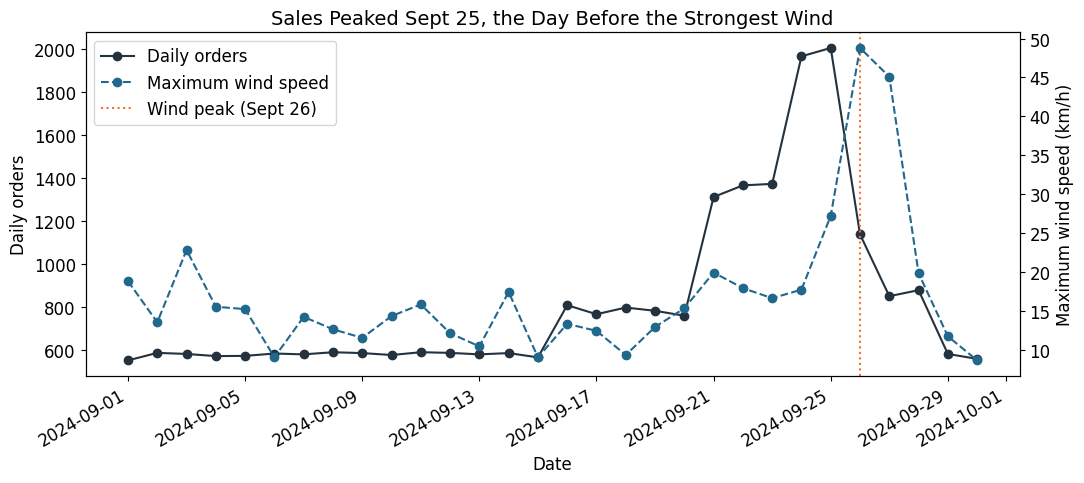

In [14]:
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "axes.titlesize": 14})

fig, ax1 = plt.subplots(figsize=(11, 5))

sales_line = ax1.plot(
    sales_weather["date"],
    sales_weather["orders"],
    marker="o",
    color="#24323E",
    label="Daily orders"
)
ax1.set_xlabel("Date")
ax1.set_ylabel("Daily orders")

ax2 = ax1.twinx()

wind_line = ax2.plot(
    sales_weather["date"],
    sales_weather["windspeed_10m_max"],
    marker="o",
    linestyle="--",
    color="#21688D",
    label="Maximum wind speed"
)
ax2.set_ylabel("Maximum wind speed (km/h)")

wind_peak = ax1.axvline(
    pd.Timestamp("2024-09-26"),
    color="#F67132",
    linestyle=":",
    label="Wind peak (Sept 26)"
)

lines = sales_line + wind_line + [wind_peak]
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="upper left")

plt.title("Sales Peaked Sept 25, the Day Before the Strongest Wind")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [15]:
category_map = {
    "emergency": "Emergency",
    "emergency supplies": "Emergency",
    "groceries": "Grocery",
    "grocery": "Grocery",
    "electronics": "Electronics",
    "entertainment": "Entertainment",
    "games & entertainment": "Entertainment",
    "household": "Household",
    "household essentials": "Household",
    "baby": "Baby",
    "baby products": "Baby",
    "breakfast": "Breakfast",
    "breakfast foods": "Breakfast",
    "alcohol": "Alcohol",
    "alcoholic beverages": "Alcohol",
    "snacks": "Snacks",
    "health": "Health",
    "health & wellness": "Health"
}

sales_prepared["category_clean"] = (
    sales_prepared["category"]
    .str.strip()
    .str.lower()
    .map(category_map)
)

sales_prepared["category_clean"].value_counts()

,count
category_clean,
Emergency,7190
Grocery,3309
Entertainment,2538
Electronics,2522
Household,2350
Baby,2086
Breakfast,2062
Alcohol,1265
Health,1231


In [16]:
daily_category_sales = (
    sales_prepared
    .dropna(subset=["date", "category_clean"])
    .groupby(["date", "category_clean"])
    .size()
    .reset_index(name="orders")
)

category_weather = daily_category_sales.merge(
    weather_live,
    on="date",
    how="left"
)

category_weather.head()

,date,category_clean,orders,precipitation_sum,windspeed_10m_max,surface_pressure_mean,source
0,2024-09-01,Alcohol,29,3.0,18.8,1009.608333,open-meteo
1,2024-09-01,Baby,62,3.0,18.8,1009.608333,open-meteo
2,2024-09-01,Breakfast,29,3.0,18.8,1009.608333,open-meteo
3,2024-09-01,Electronics,50,3.0,18.8,1009.608333,open-meteo
4,2024-09-01,Emergency,140,3.0,18.8,1009.608333,open-meteo


In [17]:
category_correlations = (
    category_weather
    .groupby("category_clean")
    .apply(
        lambda x: pd.Series({
            "precipitation_corr": x["orders"].corr(x["precipitation_sum"]),
            "wind_corr": x["orders"].corr(x["windspeed_10m_max"]),
            "pressure_corr": x["orders"].corr(x["surface_pressure_mean"])
        }),
        include_groups=False
    )
    .round(3)
)

category_correlations

,precipitation_corr,wind_corr,pressure_corr
category_clean,,,
Alcohol,-0.258,0.355,-0.213
Baby,-0.307,0.207,-0.161
Breakfast,-0.243,0.384,-0.267
Electronics,-0.245,0.350,-0.222
Emergency,-0.252,0.405,-0.292
Entertainment,-0.218,0.407,-0.283
Grocery,-0.280,0.286,-0.168
Health,-0.256,0.354,-0.253
Household,-0.226,0.382,-0.245


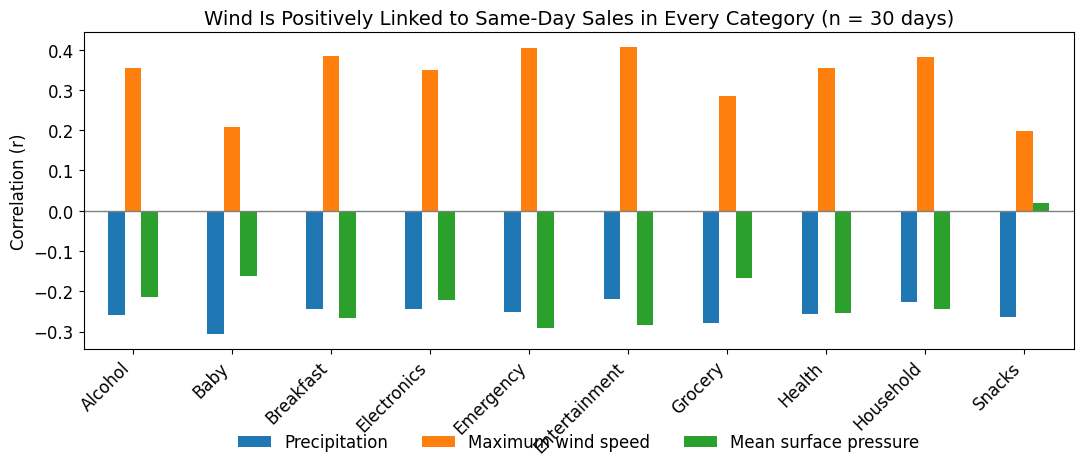

In [18]:
ax = category_correlations.rename(columns={
    "precipitation_corr": "Precipitation",
    "wind_corr": "Maximum wind speed",
    "pressure_corr": "Mean surface pressure",
}).plot(
    kind="bar",
    figsize=(11, 5)
)

ax.axhline(0, color="gray", linewidth=1)

ax.set_title("Wind Is Positively Linked to Same-Day Sales in Every Category (n = 30 days)")
ax.set_xlabel("")
ax.set_ylabel("Correlation (r)")

plt.xticks(rotation=45, ha="right")
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=3,
    frameon=False
)

plt.tight_layout()
plt.show()

In [19]:
decision_log = pd.DataFrame([
    {"step": "Duplicates", "decision": "Dropped exact duplicate rows", "rows_affected": 30},
    {"step": "Timestamps", "decision": "Parsed 5 mixed formats with format='mixed'; rows with no timestamp excluded from daily counts", "rows_affected": 884},
    {"step": "Returns", "decision": "Kept negative-quantity rows (returns) in the daily order count; they are under 1% of rows", "rows_affected": 130},
    {"step": "Categories", "decision": "Mapped 18 category spellings (after trimming and lowercasing) to 10 clean categories", "rows_affected": 0},
    {"step": "Weather location", "decision": "Used Orlando (28.54, -81.38) as one weather point for all Florida stores", "rows_affected": 0},
    {"step": "Timezone", "decision": "Requested weather in America/New_York so daily buckets match the sales data", "rows_affected": 0},
    {"step": "Join", "decision": "Left join on date so no sales day is dropped; 30 of 30 days matched", "rows_affected": 0},
    {"step": "Lag range", "decision": "Tested lags -14 to +14 days and reported n pairs for each", "rows_affected": 0},
])
decision_log

,step,decision,rows_affected
0,Duplicates,Dropped exact duplicate rows,30
1,Timestamps,Parsed 5 mixed formats with format='mixed'; ro...,884
2,Returns,Kept negative-quantity rows (returns) in the d...,130
3,Categories,Mapped 18 category spellings (after trimming a...,0
4,Weather location,"Used Orlando (28.54, -81.38) as one weather po...",0
5,Timezone,Requested weather in America/New_York so daily...,0
6,Join,Left join on date so no sales day is dropped; ...,0
7,Lag range,Tested lags -14 to +14 days and reported n pai...,0


### Q3: Weather and Sales

On the day of sale, maximum wind speed was moderately positively correlated with daily sales (r = 0.375, n = 30), while precipitation (r = -0.253, n = 30) and mean surface pressure (r = -0.255, n = 30) were weakly negatively correlated with sales. The correlation between pressure and wind is reasonable since low pressure was associated with high winds (r = -0.702). Category-level results showed the same pattern. There were 30 days of data in each category, and there were positive correlations with wind in all categories, varying from 0.199 in Snacks to 0.407 in Entertainment. The consistency of the results across categories indicates that all categories followed the same sales schedule.

The lag analysis between -14 and +14 days indicated a stronger correlation. The highest correlation was recorded at a lag of -2 days (r = 0.834, n = 28 pairs), indicating that higher sales were observed about two days before higher wind speeds. Sales reached their peak on September 24–25 with 1,968 and 2,007 orders, while the maximum wind speed occurred on September 26 at 48.8 km/h, the day of landfall.

In general, buying behavior happened in the days prior to the peak weather instead of on the day itself. Since the analysis is done for only one month's worth of data, the findings must be taken as a pattern in this specific set of data instead of causal effects of the weather.
